# PFSP: NEH vs RandNEH (biased randomisation) e ILS-ESP completo

**Problema.** Permutation Flow-Shop Problem, objetivo *makespan*. `p[j,k]` = tiempo del trabajo `j` en la máquina `k`; todos los trabajos pasan por las máquinas en el mismo orden y en el mismo orden de permutación.

**Qué se compara**
1. **Experimento A – solo constructivo.** NEH determinista frente a RandNEH con distintas distribuciones de *biased randomisation* (triangular discreta del PDF, geométrica truncada con varios β, uniforme como control).
2. **Experimento B – ILS-ESP completo** (RandNEH + búsqueda local por inserción + *enhanced swap* + aceptación *Demon*), cambiando solo la distribución usada para la solución inicial.

**Instancias** (Taillard): tai001 (20×5), tai051 (50×20), tai081 (100×20), tai101 (200×20), tai117 (500×20). **GAP %** = 100·(valor − BKS)/BKS.

Numba (`@njit`) se usa en makespan, aceleración de Taillard, RandNEH, búsqueda local, operador de perturbación y bucle ILS. Todo el código está en este notebook.

In [1]:
import os, time, math, warnings
from dataclasses import dataclass
from pathlib import Path
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# --- parámetros del estudio (cambiar aquí para ampliar/reducir el coste) ---
DATA_DIR   = Path("../data") if Path("../data").exists() else Path("data")
RESULTS_DIR = Path("../results") if Path("../results").exists() else Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
INSTANCES  = ["tai001_20_5", "tai051_50_20", "tai081_100_20", "tai101_200_20", "tai117_500_20"]
N_REPS_A   = 200      # construcciones RandNEH por (instancia, distribución)
N_SEEDS_B  = 10       # ejecuciones independientes de ILS-ESP por (instancia, inicialización)
TIME_FACTOR = 2.0     # ms por (n·m) de presupuesto de ILS-ESP (el PDF usa 10 ms·n·m)
N_PROCS    = min(2, os.cpu_count() or 1)
BASE_SEED  = 2024

BKS = {"tai001_20_5": 1278, "tai051_50_20": 3846, "tai081_100_20": 6171,
       "tai101_200_20": 11158, "tai117_500_20": 26389}
PROVEN_OPTIMAL = {"tai101_200_20", "tai117_500_20"}   # columna Optimal=1 del CSV de Zenodo
def gap_pct(v, bks): return 100.0 * (np.asarray(v, dtype=float) - bks) / bks

## 1. Instancias y BKS
`BKS` sale de la tabla de Taillard (tai001: UB 1278) y del CSV de Zenodo (resto). Solo tai101 y tai117 están demostradas óptimas; en tai001, tai051 y tai081 el BKS es el mejor valor conocido, así que un GAP ligeramente negativo sería posible en teoría (no esperable).

In [2]:
def read_instance(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#"):
            rows.append([int(x) for x in line.split()])
    (n, m), data = rows[0], rows[1:]
    assert len(data) == n and all(len(r) == m for r in data), f"{path}: dimensiones inconsistentes"
    return np.array(data, dtype=np.int64)

P = {name: read_instance(DATA_DIR / f"{name}_inputs.txt") for name in INSTANCES}
pd.DataFrame({
    "instancia": INSTANCES,
    "n": [P[k].shape[0] for k in INSTANCES], "m": [P[k].shape[1] for k in INSTANCES],
    "BKS": [BKS[k] for k in INSTANCES],
    "BKS óptimo demostrado": [k in PROVEN_OPTIMAL for k in INSTANCES],
})

,instancia,n,m,BKS,BKS óptimo demostrado
0,tai001_20_5,20,5,1278,False
1,tai051_50_20,50,20,3846,False
2,tai081_100_20,100,20,6171,False
3,tai101_200_20,200,20,11158,True
4,tai117_500_20,500,20,26389,True


## 2. Núcleo en Numba: makespan y aceleración de Taillard

* `calc_makespan`: recurrencia `C[i][k] = max(C[i-1][k], C[i][k-1]) + p`, O(n·m).
* `insert_best_position`: mueve el trabajo `perm[k]` a la mejor posición dentro de `perm[0..k]` en O(k·m) con las matrices `e` (hacia delante), `q` (hacia atrás) y `f` (trabajo nuevo). Desempate: posición más a la izquierda (como el PDF).

In [3]:
@njit(cache=True)
def calc_makespan(p, perm, length):
    m = p.shape[1]
    c = np.zeros(m, dtype=np.int64)
    for i in range(length):
        job = perm[i]
        c[0] += p[job, 0]
        for k in range(1, m):
            c[k] = max(c[k], c[k - 1]) + p[job, k]
    return c[m - 1]

@njit(cache=True)
def insert_best_position(p, perm, k):
    m = p.shape[1]
    new = perm[k]
    e = np.empty((k, m), dtype=np.int64)
    for i in range(k):
        job = perm[i]
        for j in range(m):
            if i == 0 and j == 0:
                e[0, 0] = p[job, 0]
            elif j == 0:
                e[i, 0] = e[i - 1, 0] + p[job, 0]
            elif i == 0:
                e[0, j] = e[0, j - 1] + p[job, j]
            else:
                e[i, j] = max(e[i - 1, j], e[i, j - 1]) + p[job, j]
    q = np.zeros((k + 1, m), dtype=np.int64)
    for i in range(k - 1, -1, -1):
        job = perm[i]
        for j in range(m - 1, -1, -1):
            if j == m - 1:
                q[i, j] = q[i + 1, j] + p[job, j]
            else:
                q[i, j] = max(q[i + 1, j], q[i, j + 1]) + p[job, j]
    best_pos = 0
    best_mk = np.int64(1) << 62
    for i in range(k + 1):
        mk_i = np.int64(0)
        f_prev = np.int64(0)
        for j in range(m):
            above = e[i - 1, j] if i > 0 else np.int64(0)
            f_ij = above + p[new, 0] if j == 0 else max(above, f_prev) + p[new, j]
            f_prev = f_ij
            tot = f_ij + q[i, j]
            if tot > mk_i:
                mk_i = tot
        if mk_i < best_mk:          # '<' estricto -> gana la posición más a la izquierda
            best_mk = mk_i
            best_pos = i
    for i in range(k, best_pos, -1):
        perm[i] = perm[i - 1]
    perm[best_pos] = new
    return best_mk

def makespan_slow(p, perm):
    # verificación independiente en Python puro
    n, m = len(perm), p.shape[1]
    C = np.zeros((n, m), dtype=np.int64)
    for i, j_ in enumerate(perm):
        for k in range(m):
            up = C[i-1, k] if i else 0
            left = C[i, k-1] if k else 0
            C[i, k] = max(up, left) + p[j_, k]
    return int(C[-1, -1])

## 3. RandNEH con *biased randomisation*

NEH ordena los trabajos por tiempo total de procesamiento (TPT) decreciente. **RandNEH** (Juan et al.) no toma siempre el primero de los que quedan: elige la posición `pos` de esa lista con una distribución sesgada hacia las primeras posiciones. Las distribuciones, con `r` = nº de trabajos que quedan:

| Código | Distribución | `pos` |
|---|---|---|
| `NEH` | determinista (β→1) | `0` |
| `Tri` | triangular decreciente discretizada (la del PDF, sin parámetros) | `floor(r·(1−√(1−u)))` |
| `Geo(β)` | geométrica truncada a `r` posiciones | `floor(ln(1−u·(1−(1−β)^r))/ln(1−β))` |
| `Unif` | uniforme (control: sin sesgo) | `floor(r·u)` |

Nota: el PDF da `X = b·(1−√(1−u))` sin definir `b`; aquí `b = r` (supuesto). Con esa `b` la triangular es poco concentrada cuando `r` es grande (posición media ≈ r/3), mientras que la geométrica con β fijo mantiene el mismo sesgo para cualquier `r`.

In [4]:
KIND_NEH, KIND_UNIF, KIND_TRI, KIND_GEO = 0, 1, 2, 3

@njit(cache=True)
def seed_numba(s):
    np.random.seed(s)

@njit(cache=True)
def sample_pos(r, kind, beta):
    u = np.random.random()
    if kind == KIND_NEH:
        return 0
    if kind == KIND_UNIF:
        pos = int(r * u)
    elif kind == KIND_TRI:
        pos = int(r * (1.0 - np.sqrt(1.0 - u)))
    else:
        lb = np.log(1.0 - beta)
        tail = (1.0 - beta) ** r
        pos = int(np.log(1.0 - u * (1.0 - tail)) / lb)
    return min(pos, r - 1)

@njit(cache=True)
def sample_many(r, kind, beta, N):
    out = np.empty(N, dtype=np.int64)
    for i in range(N):
        out[i] = sample_pos(r, kind, beta)
    return out

@njit(cache=True)
def rand_neh(p, order, kind, beta):
    # order: trabajos por TPT decreciente. Devuelve (perm, makespan).
    n = order.shape[0]
    remaining = order.copy()
    perm = np.empty(n, dtype=np.int64)
    mk = np.int64(0)
    r = n
    for step in range(n):
        pos = sample_pos(r, kind, beta)
        perm[step] = remaining[pos]
        for t in range(pos, r - 1):      # eliminar de la lista
            remaining[t] = remaining[t + 1]
        r -= 1
        if step == 0:
            mk = calc_makespan(p, perm, 1)
        else:
            mk = insert_best_position(p, perm, step)
    return perm, mk

def tpt_order(p):
    return np.argsort(-p.sum(axis=1), kind="stable").astype(np.int64)   # desempate: ID menor primero

# (nombre, kind, beta) -- configuraciones estudiadas
CONFIGS = [("NEH", KIND_NEH, 0.0), ("Tri", KIND_TRI, 0.0),
           ("Geo(0.05)", KIND_GEO, 0.05), ("Geo(0.1)", KIND_GEO, 0.1), ("Geo(0.2)", KIND_GEO, 0.2),
           ("Geo(0.3)", KIND_GEO, 0.3), ("Geo(0.5)", KIND_GEO, 0.5), ("Unif", KIND_UNIF, 0.0)]
CFG = {c[0]: c for c in CONFIGS}

# calentamiento de la compilación
_p = P["tai001_20_5"]; seed_numba(0)
_ = [rand_neh(_p, tpt_order(_p), c[1], c[2]) for c in CONFIGS]

### 3.1 Validación
Antes de experimentar: (i) NEH con aceleración de Taillard = NEH ingenuo con recurrencia directa; (ii) el makespan devuelto por RandNEH coincide con el recalculado desde cero; (iii) tai117 reproduce el valor del PDF (26797 con el NEH determinista).

In [5]:
def neh_naive(p):
    # NEH sin aceleración: prueba cada posición con la recurrencia directa (lento, solo para validar)
    perm = []
    for job in tpt_order(p):
        best, best_pos = None, 0
        for pos in range(len(perm) + 1):
            cand = perm[:pos] + [int(job)] + perm[pos:]
            v = makespan_slow(p, cand)
            if best is None or v < best:
                best, best_pos = v, pos
        perm.insert(best_pos, int(job))
    return perm, best

for name in ["tai001_20_5", "tai051_50_20"]:
    p = P[name]
    perm, mk = rand_neh(p, tpt_order(p), KIND_NEH, 0.0)
    perm_ref, mk_ref = neh_naive(p)
    assert list(perm) == perm_ref and mk == mk_ref, name
    print(f"{name}: NEH acelerado == NEH ingenuo  (makespan {mk})")

seed_numba(1)
for name in INSTANCES:
    p = P[name]
    for cfg in CONFIGS:
        perm, mk = rand_neh(p, tpt_order(p), cfg[1], cfg[2])
        assert sorted(perm) == list(range(p.shape[0])) and mk == makespan_slow(p, perm)
print("RandNEH: permutaciones válidas y makespan verificado para todas las instancias y distribuciones")

p = P["tai117_500_20"]
mk117 = rand_neh(p, tpt_order(p), KIND_NEH, 0.0)[1]
print("NEH tai117 =", mk117, "(PDF: 26797)")
assert mk117 == 26797

tai001_20_5: NEH acelerado == NEH ingenuo  (makespan 1286)


tai051_50_20: NEH acelerado == NEH ingenuo  (makespan 4082)
RandNEH: permutaciones válidas y makespan verificado para todas las instancias y distribuciones
NEH tai117 = 26797 (PDF: 26797)


### 3.2 Cómo reparte cada distribución la probabilidad entre los candidatos
Probabilidad de elegir cada posición de la lista ordenada por TPT, con `r = 20` y `r = 100` candidatos.

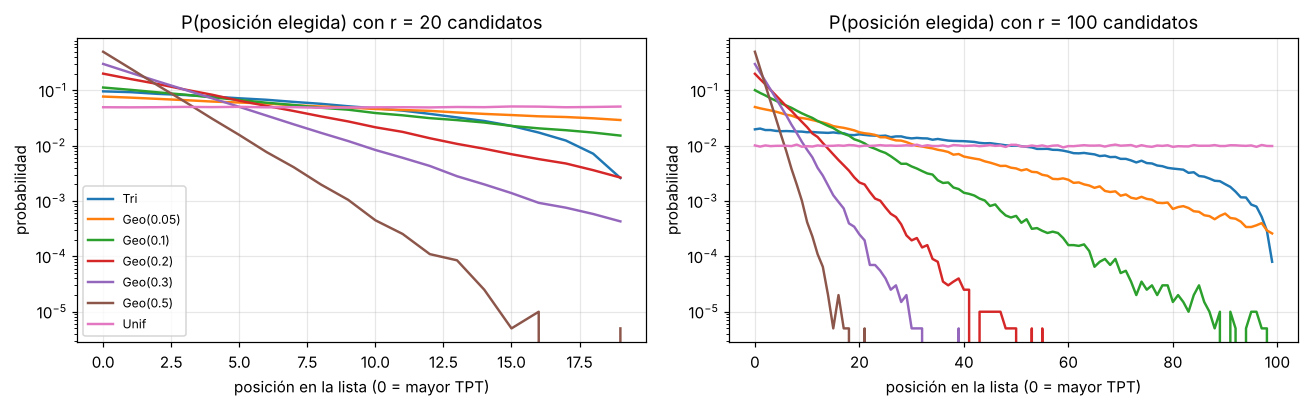

Posición media elegida (0 = el primero de la lista):


,Tri,Geo(0.05),Geo(0.1),Geo(0.2),Geo(0.3),Geo(0.5),Unif
r,,,,,,,
20,6.19,7.82,6.23,3.76,2.33,1.0,9.50
100,32.75,18.35,9.02,4.01,2.34,1.0,49.51
500,165.64,19.07,8.98,4.00,2.32,1.0,249.67


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
seed_numba(7)
for ax, r in zip(axes, [20, 100]):
    for name, kind, beta in CONFIGS[1:]:
        s = sample_many(r, kind, beta, 200_000)
        pmf = np.bincount(s, minlength=r) / len(s)
        ax.plot(range(r), pmf, label=name, lw=1.6)
    ax.set_title(f"P(posición elegida) con r = {r} candidatos"); ax.set_xlabel("posición en la lista (0 = mayor TPT)")
    ax.set_yscale("log"); ax.set_ylabel("probabilidad")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for r in [20, 100, 500]:
    row = {"r": r}
    for name, kind, beta in CONFIGS[1:]:
        row[name] = sample_many(r, kind, beta, 200_000).mean()
    rows.append(row)
print("Posición media elegida (0 = el primero de la lista):")
pd.DataFrame(rows).set_index("r").round(2)

## 4. Experimento A – RandNEH frente a NEH (solo fase constructiva)

Para cada instancia y distribución se generan `N_REPS_A` soluciones y se mide el GAP. NEH es determinista (una sola solución, repetida). Métricas: GAP medio y desviación, mejor GAP de las `N_REPS_A`, y % de construcciones que mejoran al NEH.

In [7]:
def run_A():
    rows, raw = [], []
    for name in INSTANCES:
        p = P[name]; order = tpt_order(p); bks = BKS[name]
        neh_mk = rand_neh(p, order, KIND_NEH, 0.0)[1]
        for ci, (cname, kind, beta) in enumerate(CONFIGS):
            seed_numba(BASE_SEED + 1000 * ci)
            reps = 1 if kind == KIND_NEH else N_REPS_A
            mks = np.empty(reps, dtype=np.int64)
            t0 = time.perf_counter()
            for i in range(reps):
                mks[i] = rand_neh(p, order, kind, beta)[1]
            dt = (time.perf_counter() - t0) / reps * 1000
            g = gap_pct(mks, bks)
            rows.append(dict(instancia=name, dist=cname, reps=reps, gap_medio=g.mean(), gap_std=g.std(ddof=0),
                             gap_mejor=g.min(), gap_peor=g.max(), pct_mejora_NEH=100 * np.mean(mks < neh_mk),
                             ms_por_construccion=dt, makespan_NEH=neh_mk))
            raw += [dict(instancia=name, dist=cname, makespan=int(v), gap=float(x)) for v, x in zip(mks, g)]
    return pd.DataFrame(rows), pd.DataFrame(raw)

resA, rawA = run_A()
resA.to_csv(RESULTS_DIR / "expA_randneh_resumen.csv", index=False)
rawA.to_csv(RESULTS_DIR / "expA_randneh_raw.csv", index=False)
tabA = resA.pivot(index="dist", columns="instancia", values="gap_medio").reindex([c[0] for c in CONFIGS])[INSTANCES]
print("GAP medio (%) de la solución constructiva:")
tabA.round(3)

GAP medio (%) de la solución constructiva:


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
dist,,,,,
NEH,0.626,6.136,5.996,3.908,1.546
Tri,1.797,6.549,6.954,4.582,1.832
Geo(0.05),2.112,6.428,6.870,4.506,1.689
Geo(0.1),1.993,6.239,6.621,4.423,1.652
Geo(0.2),1.819,5.989,6.453,4.343,1.612
Geo(0.3),1.569,5.893,6.463,4.310,1.613
Geo(0.5),1.231,5.681,6.534,4.305,1.588
Unif,2.082,6.902,7.246,4.877,2.111


In [8]:
cols = ["instancia", "dist", "gap_medio", "gap_std", "gap_mejor", "pct_mejora_NEH", "ms_por_construccion"]
resA[cols].round(3).pivot_table(index="dist", columns="instancia", values=["gap_medio", "gap_mejor", "pct_mejora_NEH"]) \
    .reindex([c[0] for c in CONFIGS], level=0).round(2)

gap_medio                                                         \
instancia tai001_20_5 tai051_50_20 tai081_100_20 tai101_200_20 tai117_500_20   
dist                                                                           
NEH              0.63         6.14          6.00          3.91          1.55   
Tri              1.80         6.55          6.95          4.58          1.83   
Geo(0.05)        2.11         6.43          6.87          4.51          1.69   
Geo(0.1)         1.99         6.24          6.62          4.42          1.65   
Geo(0.2)         1.82         5.99          6.45          4.34          1.61   
Geo(0.3)         1.57         5.89          6.46          4.31          1.61   
Geo(0.5)         1.23         5.68          6.53          4.30          1.59   
Unif             2.08         6.90          7.25          4.88          2.11   

            gap_mejor                                                         \
instancia tai001_20_5 tai051_50_20 tai081_100_20 tai101_200_20 tai117_500_20   
dist                                                                           
NEH              0.63         6.14          6.00          3.91          1.55   
Tri              0.00         4.13          5.44          3.67          1.24   
Geo(0.05)        0.00         3.95          5.30          3.40          1.18   
Geo(0.1)         0.00         4.24          4.96          3.42          1.18   
Geo(0.2)         0.00         4.26          5.06          3.52          1.16   
Geo(0.3)         0.00         4.11          5.15          3.38          1.00   
Geo(0.5)         0.00         2.94          4.97          3.24          1.16   
Unif             0.31         4.76          5.11          3.80          1.49   

          pct_mejora_NEH                                           \
instancia    tai001_20_5 tai051_50_20 tai081_100_20 tai101_200_20   
dist                                                                
NEH                  0.0          0.0           0.0           0.0   
Tri                  3.0         32.0           6.5           6.0   
Geo(0.05)            2.0         34.0           7.0           6.0   
Geo(0.1)             3.5         43.5          14.5           9.0   
Geo(0.2)             6.5         58.0          19.0          10.5   
Geo(0.3)            10.0         64.5          20.5          13.0   
Geo(0.5)            17.0         74.5          18.0          15.0   
Unif                 1.5         19.0           1.5           1.0   

                         
instancia tai117_500_20  
dist                     
NEH                 0.0  
Tri                12.0  
Geo(0.05)          26.5  
Geo(0.1)           33.0  
Geo(0.2)           40.0  
Geo(0.3)           33.0  
Geo(0.5)           40.0  
Unif                0.5

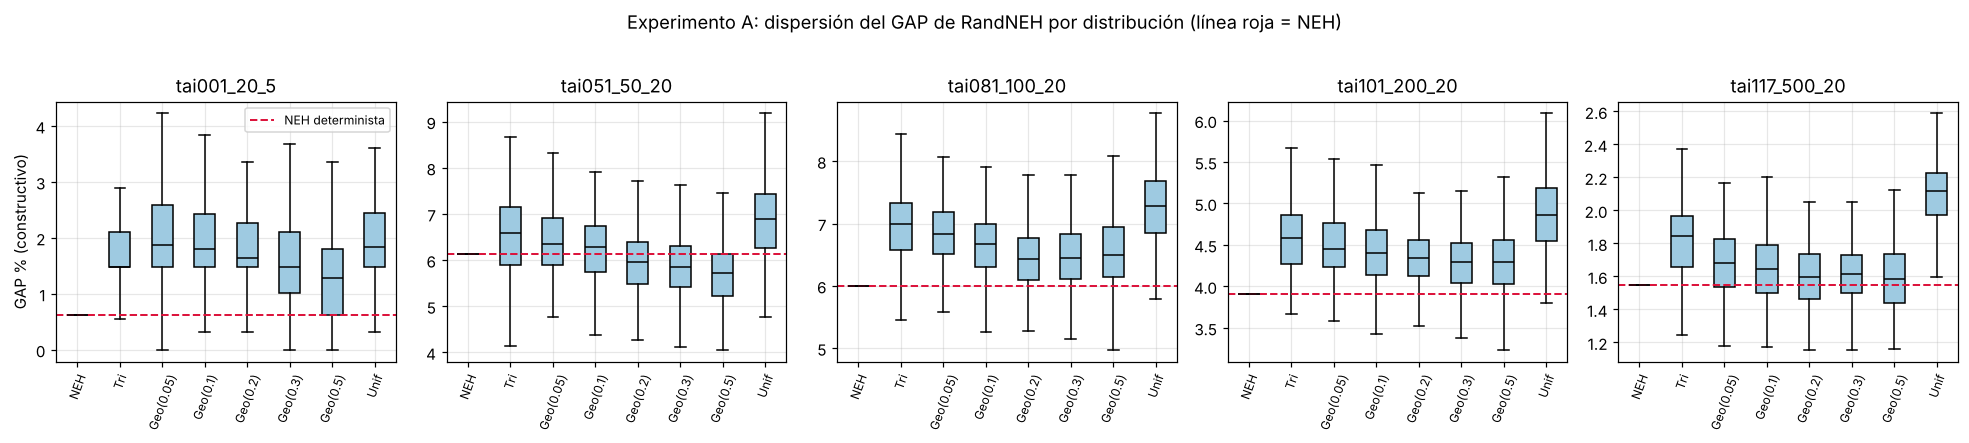

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
order_names = [c[0] for c in CONFIGS]
for ax, name in zip(axes, INSTANCES):
    d = rawA[rawA.instancia == name]
    data = [d[d.dist == c].gap.values for c in order_names]
    ax.boxplot(data, tick_labels=order_names, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="k"))
    neh_gap = d[d.dist == "NEH"].gap.iloc[0]
    ax.axhline(neh_gap, color="crimson", ls="--", lw=1.3, label="NEH determinista")
    ax.set_title(name); ax.tick_params(axis="x", rotation=70, labelsize=8)
    ax.set_ylabel("GAP % (constructivo)" if name == INSTANCES[0] else "")
axes[0].legend(fontsize=8)
plt.suptitle("Experimento A: dispersión del GAP de RandNEH por distribución (línea roja = NEH)", y=1.02)
plt.tight_layout(); plt.show()

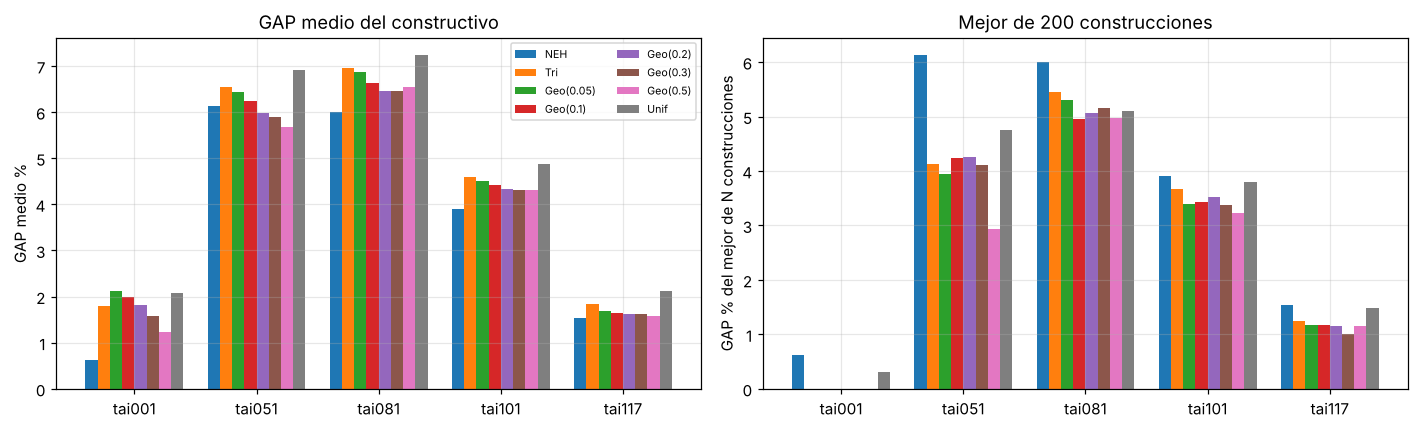

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(INSTANCES)); w = 0.8 / len(CONFIGS)
for i, c in enumerate(order_names):
    axes[0].bar(x + i * w, tabA.loc[c, INSTANCES].values, w, label=c)
axes[0].set_xticks(x + 0.4 - w / 2); axes[0].set_xticklabels([n.split("_")[0] for n in INSTANCES])
axes[0].set_ylabel("GAP medio %"); axes[0].set_title("GAP medio del constructivo"); axes[0].legend(fontsize=7, ncol=2)
best = resA.pivot(index="dist", columns="instancia", values="gap_mejor").reindex(order_names)[INSTANCES]
for i, c in enumerate(order_names):
    axes[1].bar(x + i * w, best.loc[c].values, w, label=c)
axes[1].set_xticks(x + 0.4 - w / 2); axes[1].set_xticklabels([n.split("_")[0] for n in INSTANCES])
axes[1].set_ylabel("GAP % del mejor de N construcciones"); axes[1].set_title(f"Mejor de {N_REPS_A} construcciones")
plt.tight_layout(); plt.show()

## 5. ILS-ESP completo

Pseudocódigo (diapositivas 43-44; la diapositiva escribe `localSearch(baseSol)` donde debe ir `currentSol`, lo corregimos):

```
baseSol = RandNEH();  baseSol = localSearch(baseSol);  bestSol = baseSol
while not endCondition:
    currentSol = enhancedSwap(baseSol)          # perturbación
    currentSol = localSearch(currentSol)
    delta = cost(currentSol) - cost(baseSol)
    if delta < 0:   baseSol = currentSol; lastImprovement = -delta; lastWasImp = True; actualiza bestSol
    elif delta > 0 and lastWasImp and delta <= lastImprovement:
                    baseSol = currentSol; lastWasImp = False        # Demon: degradación permitida
```
* **Enhanced swap**: dos posiciones al azar distintas, se intercambian y se hace *shift-to-left* (mejor posición hacia la izquierda, con Taillard) del trabajo en la posición menor y luego del de la mayor.
* **Búsqueda local**: inserción. Se recorren todos los trabajos en orden aleatorio; cada uno se extrae y se reinserta en su mejor posición (Taillard); se repite hasta que una pasada completa no mejora.
* **Sin parámetros**. El criterio de parada es el tiempo: `TIME_FACTOR · n · m` ms. El reloj se comprueba desde Python entre bloques de iteraciones (Numba no tiene `time` en modo nopython), así que la curva de convergencia se registra en esos puntos.

In [11]:
@njit(cache=True)
def local_search(p, perm, mk):
    # Búsqueda local por inserción (best-improvement por trabajo, recorrido aleatorio). In situ.
    n = perm.shape[0]
    improved = True
    while improved:
        improved = False
        jobs = np.random.permutation(n)
        for idx in range(n):
            job = jobs[idx]
            pos = 0
            while perm[pos] != job:
                pos += 1
            for t in range(pos, n - 1):          # llevar el trabajo al final...
                perm[t] = perm[t + 1]
            perm[n - 1] = job
            new_mk = insert_best_position(p, perm, n - 1)   # ...y reinsertarlo en su mejor posición
            if new_mk < mk:
                mk = new_mk
                improved = True
    return mk

@njit(cache=True)
def ils_esp_chunk(p, base, best, st, iters):
    # st = [makespan base, makespan best, lastImprovement, lastWasImprovement]
    n = base.shape[0]
    cur = base.copy()
    for _ in range(iters):
        cur[:] = base
        a = np.random.randint(0, n)
        b = np.random.randint(0, n)
        while b == a:
            b = np.random.randint(0, n)
        tmp = cur[a]; cur[a] = cur[b]; cur[b] = tmp          # intercambio
        lo = min(a, b); hi = max(a, b)
        insert_best_position(p, cur, lo)                     # shift-to-left ordenado
        insert_best_position(p, cur, hi)
        cur_mk = calc_makespan(p, cur, n)
        cur_mk = local_search(p, cur, cur_mk)
        delta = cur_mk - st[0]
        if delta < 0:
            st[3] = 1; st[2] = -delta
            base[:] = cur; st[0] = cur_mk
            if cur_mk < st[1]:
                best[:] = cur; st[1] = cur_mk
        elif delta > 0 and st[3] == 1 and delta <= st[2]:
            st[3] = 0
            base[:] = cur; st[0] = cur_mk

def ils_esp(p, kind, beta, budget_s, seed, order=None):
    # Devuelve dict con GAP-independiente: makespan inicial, tras LS, final, traza (t, best) e iteraciones.
    seed_numba(seed)
    order = tpt_order(p) if order is None else order
    t0 = time.perf_counter()
    base, mk0 = rand_neh(p, order, kind, beta)
    base = base.copy()
    mk_ls = local_search(p, base, mk0)
    best = base.copy()
    st = np.array([mk_ls, mk_ls, 0, 0], dtype=np.int64)
    trace_t, trace_b = [time.perf_counter() - t0], [int(st[1])]
    iters, chunk = 0, 1
    while True:
        elapsed = time.perf_counter() - t0
        if elapsed >= budget_s:
            break
        c0 = time.perf_counter()
        ils_esp_chunk(p, base, best, st, chunk)
        iters += chunk
        dt = time.perf_counter() - c0
        trace_t.append(time.perf_counter() - t0); trace_b.append(int(st[1]))
        # bloques de ~20 ms o menos, y sin pasarse del presupuesto
        chunk = int(max(1, min(1000, 0.02 / max(dt / chunk, 1e-7))))
    return dict(mk_init=int(mk0), mk_ls=int(mk_ls), mk_final=int(st[1]), perm=best.copy(),
                trace_t=np.array(trace_t), trace_b=np.array(trace_b), iters=iters,
                time=time.perf_counter() - t0)

# calentamiento + comprobación de que el resultado es consistente
_p = P["tai051_50_20"]
r = ils_esp(_p, KIND_TRI, 0.0, 0.5, 1)
assert sorted(r["perm"]) == list(range(_p.shape[0])) and r["mk_final"] == makespan_slow(_p, r["perm"])
print(f"smoke test tai051: init {r['mk_init']} -> LS {r['mk_ls']} -> ILS-ESP {r['mk_final']}  ({r['iters']} iteraciones en {r['time']:.2f}s)")

smoke test tai051: init 4133 -> LS 3994 -> ILS-ESP 3918  (388 iteraciones en 0.50s)


## 6. Experimento B – ILS-ESP con distintas inicializaciones

Se mantiene el ILS-ESP intacto y solo se cambia la distribución de la solución inicial: `NEH` (determinista), `Tri` (la del algoritmo original), `Geo(0.1)`, `Geo(0.3)` y `Unif`. Cada combinación se ejecuta con `N_SEEDS_B` semillas independientes y presupuesto `TIME_FACTOR · n · m` ms (el mismo tiempo para todas, la construcción inicial incluida). Las ejecuciones se reparten en `N_PROCS` procesos; con presupuesto por tiempo real, la carga del equipo introduce algo de ruido entre ejecuciones.

In [12]:
INITS = ["NEH", "Tri", "Geo(0.1)", "Geo(0.3)", "Unif"]
GRID = np.linspace(0, 1, 101)       # fracción del presupuesto, para promediar curvas

def job_B(args):
    name, init, seed, budget = args
    p = P[name]
    _, kind, beta = CFG[init]
    r = ils_esp(p, kind, beta, budget, seed)
    bks = BKS[name]
    # curva de convergencia: mejor makespan en cada fracción del presupuesto
    idx = np.searchsorted(r["trace_t"], GRID * budget, side="right") - 1
    curve = gap_pct(r["trace_b"][np.clip(idx, 0, None)], bks)
    assert r["mk_final"] == makespan_slow(p, r["perm"])
    return dict(instancia=name, init=init, seed=seed, budget_s=budget,
                gap_init=float(gap_pct(r["mk_init"], bks)), gap_tras_LS=float(gap_pct(r["mk_ls"], bks)),
                gap_final=float(gap_pct(r["mk_final"], bks)), makespan_final=r["mk_final"],
                iters=r["iters"], curve=curve)

tasks = []
for name in INSTANCES:
    n, m = P[name].shape
    budget = TIME_FACTOR * n * m / 1000.0
    for ii, init in enumerate(INITS):
        for s in range(N_SEEDS_B):
            tasks.append((name, init, BASE_SEED + 100 * ii + s, budget))
# las más largas primero para equilibrar los procesos
tasks.sort(key=lambda t: -t[3])
est = sum(t[3] for t in tasks) / N_PROCS
print(f"{len(tasks)} ejecuciones; tiempo estimado ≈ {est/60:.1f} min con {N_PROCS} procesos")

250 ejecuciones; tiempo estimado ≈ 14.2 min con 2 procesos


In [13]:
t0 = time.time()
ctx = mp.get_context("fork")
with ctx.Pool(N_PROCS) as pool:
    outB = pool.map(job_B, tasks, chunksize=1)
print(f"hecho en {(time.time()-t0)/60:.1f} min")
curves = {(o["instancia"], o["init"], o["seed"]): o.pop("curve") for o in outB}
resB = pd.DataFrame(outB)
resB.to_csv(RESULTS_DIR / "expB_ilsesp_raw.csv", index=False)
resB.groupby(["instancia", "init"]).agg(gap_medio=("gap_final", "mean"), gap_mejor=("gap_final", "min"),
                                         gap_std=("gap_final", "std"), iters_medias=("iters", "mean")).round(3).head(10)

hecho en 14.3 min


gap_medio  gap_mejor  gap_std  iters_medias
instancia    init                                                 
tai001_20_5  Geo(0.1)      0.000      0.000    0.000        5128.2
             Geo(0.3)      0.000      0.000    0.000        4239.0
             NEH           0.000      0.000    0.000        5150.5
             Tri           0.000      0.000    0.000        5021.9
             Unif          0.000      0.000    0.000        4511.8
tai051_50_20 Geo(0.1)      1.329      1.170    0.151        1476.2
             Geo(0.3)      1.277      1.066    0.096        1574.5
             NEH           1.303      1.222    0.088        1511.5
             Tri           1.300      0.884    0.229        1568.9
             Unif          1.126      0.494    0.296        1566.8

In [14]:
orderB = INITS
sumB = resB.groupby(["instancia", "init"]).agg(
    gap_init=("gap_init", "mean"), gap_tras_LS=("gap_tras_LS", "mean"),
    gap_final_medio=("gap_final", "mean"), gap_final_std=("gap_final", "std"),
    gap_final_mejor=("gap_final", "min"), iters=("iters", "mean")).reset_index()
sumB.to_csv(RESULTS_DIR / "expB_ilsesp_resumen.csv", index=False)
print("GAP final medio (%) de ILS-ESP — media de", N_SEEDS_B, "ejecuciones")
tab_mean = sumB.pivot(index="init", columns="instancia", values="gap_final_medio").reindex(orderB)[INSTANCES]
display(tab_mean.round(3))
print("Mejor GAP (%) entre las", N_SEEDS_B, "ejecuciones (equivale a N agentes en paralelo)")
display(sumB.pivot(index="init", columns="instancia", values="gap_final_mejor").reindex(orderB)[INSTANCES].round(3))
print("Iteraciones medias de ILS dentro del presupuesto")
display(sumB.pivot(index="init", columns="instancia", values="iters").reindex(orderB)[INSTANCES].round(0))

GAP final medio (%) de ILS-ESP — media de 10 ejecuciones


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,0.0,1.303,2.390,1.749,0.542
Tri,0.0,1.300,2.340,1.801,0.714
Geo(0.1),0.0,1.329,2.141,1.805,0.598
Geo(0.3),0.0,1.277,2.167,1.809,0.610
Unif,0.0,1.126,2.471,1.812,0.559


Mejor GAP (%) entre las 10 ejecuciones (equivale a N agentes en paralelo)


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,0.0,1.222,1.831,1.416,0.451
Tri,0.0,0.884,1.831,1.308,0.485
Geo(0.1),0.0,1.170,1.750,1.640,0.451
Geo(0.3),0.0,1.066,1.928,1.604,0.451
Unif,0.0,0.494,1.993,1.667,0.474


Iteraciones medias de ILS dentro del presupuesto


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,5150.0,1512.0,701.0,356.0,262.0
Tri,5022.0,1569.0,701.0,338.0,273.0
Geo(0.1),5128.0,1476.0,685.0,379.0,262.0
Geo(0.3),4239.0,1574.0,683.0,371.0,276.0
Unif,4512.0,1567.0,688.0,349.0,252.0


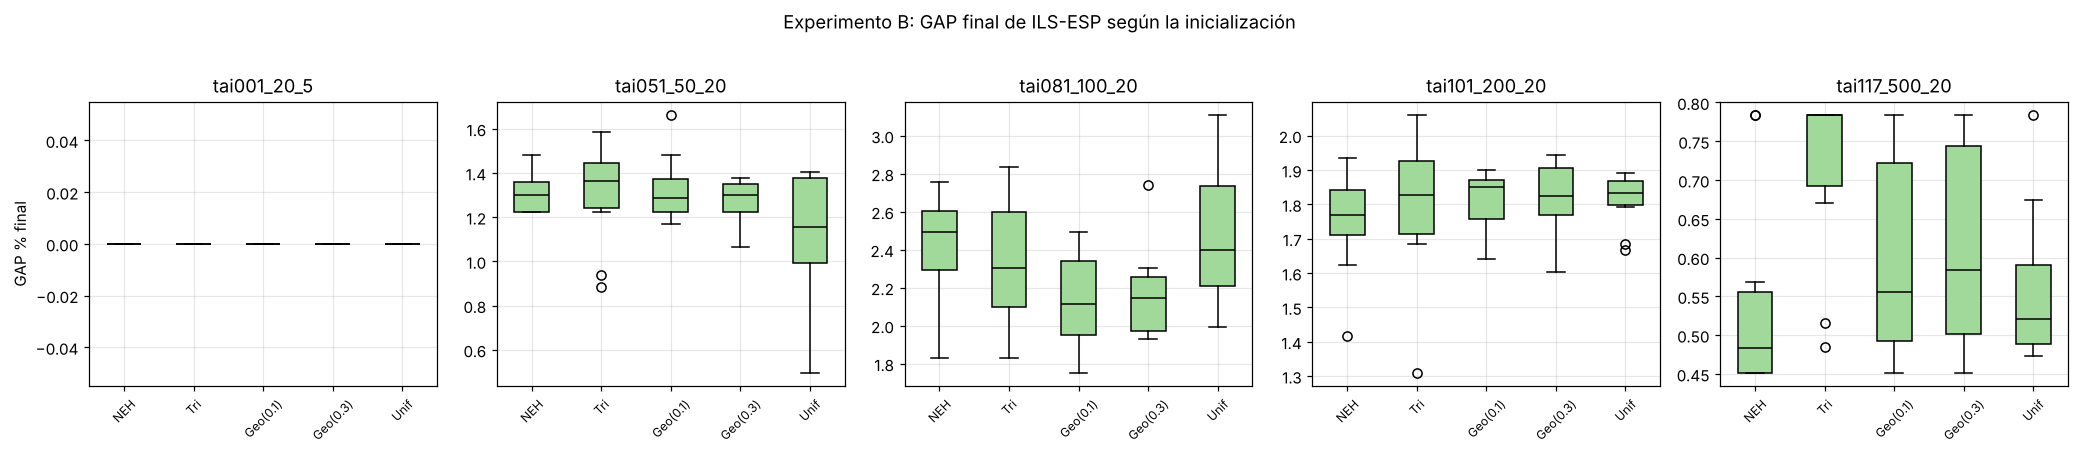

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, name in zip(axes, INSTANCES):
    d = resB[resB.instancia == name]
    ax.boxplot([d[d.init == i].gap_final.values for i in orderB], tick_labels=orderB, patch_artist=True,
               boxprops=dict(facecolor="#a1d99b"), medianprops=dict(color="k"))
    ax.set_title(name); ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.set_ylabel("GAP % final" if name == INSTANCES[0] else "")
plt.suptitle("Experimento B: GAP final de ILS-ESP según la inicialización", y=1.02)
plt.tight_layout(); plt.show()

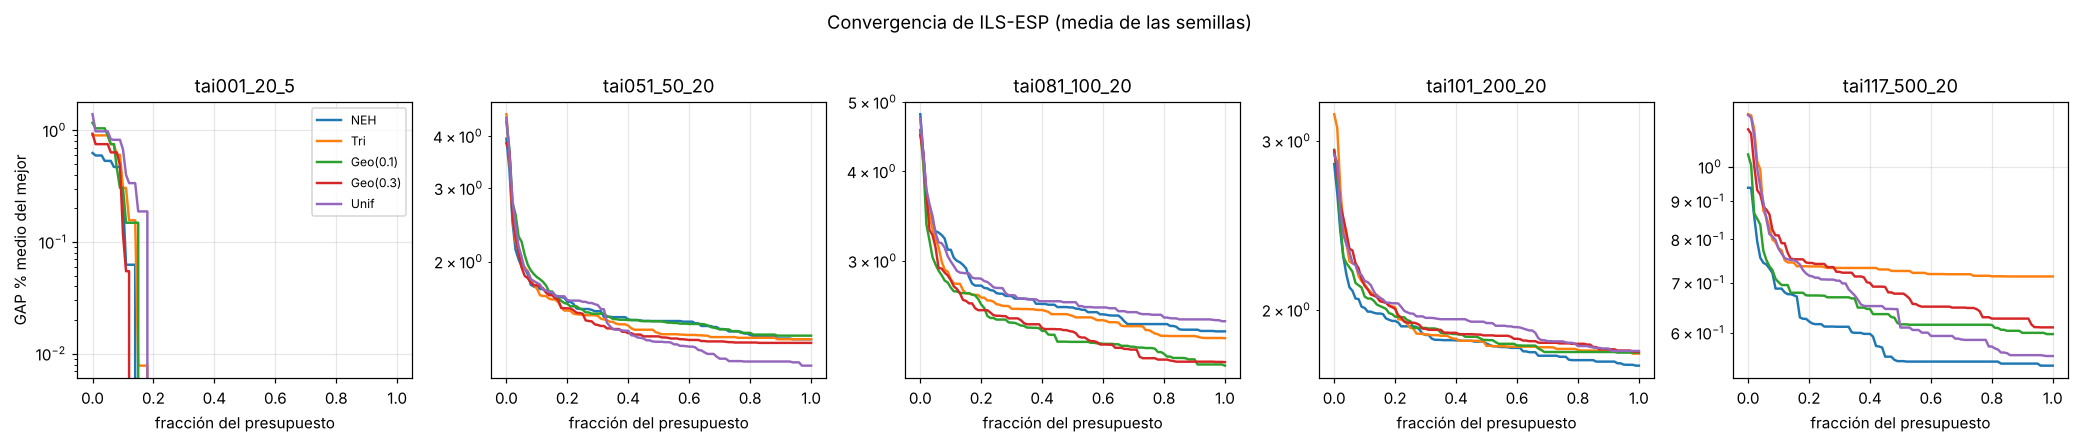

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.9))
for ax, name in zip(axes, INSTANCES):
    for init in orderB:
        cs = np.array([curves[(name, init, s)] for s in resB[(resB.instancia == name) & (resB.init == init)].seed])
        ax.plot(GRID, cs.mean(axis=0), label=init, lw=1.6)
    ax.set_title(name); ax.set_xlabel("fracción del presupuesto"); ax.set_yscale("log")
    ax.set_ylabel("GAP % medio del mejor" if name == INSTANCES[0] else "")
axes[0].legend(fontsize=8)
plt.suptitle("Convergencia de ILS-ESP (media de las semillas)", y=1.02)
plt.tight_layout(); plt.show()

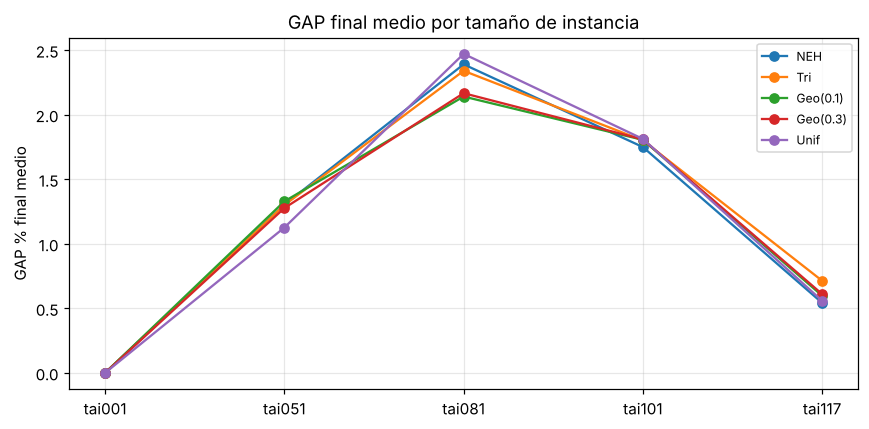

gap_init  gap_tras_LS  gap_final
instancia     init                                      
tai001_20_5   Geo(0.1)     2.238        1.166      0.000
              Geo(0.3)     1.440        0.931      0.000
              NEH          0.626        0.626      0.000
              Tri          1.510        0.908      0.000
              Unif         1.917        1.393      0.000
tai051_50_20  Geo(0.1)     6.474        4.324      1.329
              Geo(0.3)     5.939        3.846      1.277
              NEH          6.136        3.944      1.303
              Tri          6.599        4.514      1.300
              Unif         6.895        4.423      1.126
tai081_100_20 Geo(0.1)     6.936        4.570      2.141
              Geo(0.3)     6.612        4.497      2.167
              NEH          5.996        4.808      2.390
              Tri          6.594        4.555      2.340
              Unif         7.197        4.748      2.471
tai101_200_20 Geo(0.1)     4.282        2.935      1.805
              Geo(0.3)     4.562        2.931      1.809
              NEH          3.908        2.837      1.749
              Tri          4.945        3.198      1.801
              Unif         5.071        2.904      1.812
tai117_500_20 Geo(0.1)     1.602        1.039      0.598
              Geo(0.3)     1.698        1.122      0.610
              NEH          1.546        0.938      0.542
              Tri          1.879        1.176      0.714
              Unif         2.050        1.173      0.559

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
stages = ["gap_init", "gap_tras_LS", "gap_final"]
for init in orderB:
    d = resB[resB.init == init].groupby("instancia")[stages].mean().reindex(INSTANCES)
    ax.plot(range(len(INSTANCES)), d["gap_final"].values, "o-", label=init)
ax.set_xticks(range(len(INSTANCES))); ax.set_xticklabels([n.split("_")[0] for n in INSTANCES])
ax.set_ylabel("GAP % final medio"); ax.set_title("GAP final medio por tamaño de instancia"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# de dónde viene la mejora: constructivo -> búsqueda local -> ILS
stg = resB.groupby(["instancia", "init"])[stages].mean().round(3)
stg.loc[INSTANCES]

## 7. Significación estadística
Para cada instancia se compara el GAP final de cada inicialización con el de NEH determinista (test de Mann-Whitney, bilateral). Con 10 semillas por grupo, los p-valores son orientativos: no se corrigen por comparaciones múltiples. También se muestra el ranking medio (1 = mejor) de cada inicialización por instancia.

In [18]:
rows = []
for name in INSTANCES:
    base = resB[(resB.instancia == name) & (resB.init == "NEH")].gap_final.values
    for init in orderB[1:]:
        x = resB[(resB.instancia == name) & (resB.init == init)].gap_final.values
        if np.allclose(x, x[0]) and np.allclose(base, base[0]) and x[0] == base[0]:
            pval = 1.0
        else:
            pval = stats.mannwhitneyu(x, base, alternative="two-sided").pvalue
        rows.append(dict(instancia=name, init=init, dif_gap_medio_vs_NEH=x.mean() - base.mean(), p_valor=pval))
tests = pd.DataFrame(rows)
tests.to_csv(RESULTS_DIR / "expB_tests_vs_NEH.csv", index=False)
display(tests.pivot(index="init", columns="instancia", values="dif_gap_medio_vs_NEH").reindex(orderB[1:])[INSTANCES].round(3))
display(tests.pivot(index="init", columns="instancia", values="p_valor").reindex(orderB[1:])[INSTANCES].round(3))
rk = tab_mean.rank(axis=0)
rk["rank_medio"] = rk.mean(axis=1)
rk.round(2)

instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
Tri,0.0,-0.003,-0.050,0.051,0.171
Geo(0.1),0.0,0.026,-0.250,0.056,0.055
Geo(0.3),0.0,-0.026,-0.224,0.059,0.068
Unif,0.0,-0.177,0.081,0.063,0.016


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
Tri,1.0,0.467,0.705,0.406,0.013
Geo(0.1),1.0,0.938,0.075,0.384,0.281
Geo(0.3),1.0,0.786,0.112,0.325,0.124
Unif,1.0,0.380,0.820,0.307,0.254


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20,rank_medio
init,,,,,,
NEH,3.0,4.0,4.0,1.0,1.0,2.6
Tri,3.0,3.0,3.0,2.0,5.0,3.2
Geo(0.1),3.0,5.0,1.0,3.0,3.0,3.0
Geo(0.3),3.0,2.0,2.0,4.0,4.0,3.0
Unif,3.0,1.0,5.0,5.0,2.0,3.2


## 8. Comparación global y conclusiones

In [19]:
# Resumen: NEH determinista -> RandNEH(Tri) -> ILS-ESP (Tri), GAP medio por instancia
summary = pd.DataFrame({
    "NEH": tabA.loc["NEH", INSTANCES],
    "RandNEH Tri (media)": tabA.loc["Tri", INSTANCES],
    "mejor RandNEH Tri de N": resA[resA.dist == "Tri"].set_index("instancia").loc[INSTANCES, "gap_mejor"],
    "ILS-ESP (Tri), media": tab_mean.loc["Tri", INSTANCES],
    "ILS-ESP (Tri), mejor": sumB[sumB.init == "Tri"].set_index("instancia").loc[INSTANCES, "gap_final_mejor"],
})
summary.to_csv(RESULTS_DIR / "resumen_global.csv")
summary.round(3)

,NEH,RandNEH Tri (media),mejor RandNEH Tri de N,"ILS-ESP (Tri), media","ILS-ESP (Tri), mejor"
instancia,,,,,
tai001_20_5,0.626,1.797,0.000,0.000,0.000
tai051_50_20,6.136,6.549,4.134,1.300,0.884
tai081_100_20,5.996,6.954,5.445,2.340,1.831
tai101_200_20,3.908,4.582,3.666,1.801,1.308
tai117_500_20,1.546,1.832,1.243,0.714,0.485


## Conclusiones (de esta ejecución: 200 construcciones por configuración y 10 semillas de ILS-ESP con 2 ms·n·m)

**Experimento A – constructivo**
1. **En media, ningún RandNEH mejora al NEH determinista**, salvo en tai051 con geométrica de sesgo medio-alto (GAP medio 5,68–5,99 % frente a 6,14 %). En tai001, tai081, tai101 y tai117 el NEH es mejor en media (p. ej. tai101: 3,91 % frente a 4,31–4,88 %).
2. **Su valor es la diversidad.** La mejor de 200 construcciones sí supera claramente a NEH: tai051 2,94 % (Geo 0,5) vs 6,14 %; tai081 4,96 % vs 6,00 %; tai101 3,24 % vs 3,91 %; tai117 1,00 % (Geo 0,3) vs 1,55 %; y en tai001 se alcanza el BKS (GAP 0). El porcentaje de construcciones que baten al NEH va del 1 % (Unif) al 75 % (Geo 0,5 en tai051), y es bajo en tai081 y tai101 (≤ 21 %).
3. **Ranking de distribuciones por GAP medio:** geométrica con β alto (0,3–0,5) < β bajo < **triangular del PDF** < uniforme. Cuanto más sesgo hacia el principio de la lista, más cerca del NEH. La uniforme (sin sesgo) es la peor en 4 de las 5 instancias (en tai001 queda al nivel de Geo 0,05): el sesgo ayuda. La triangular con `b = r` es peor que Geo(0,3) y Geo(0,5) en las 5 instancias (frente a β ≤ 0,2 es peor en 4 de 5; en tai001 queda al mismo nivel), y la diferencia crece con el tamaño (posición media elegida con r = 500: 166 frente a ≈ 9 con Geo(0,1)). Esto depende de mi supuesto `b = r`, que el PDF no define.
4. Coste: una construcción cuesta lo mismo que el NEH (≈ 14 ms en tai117); la aleatorización no añade tiempo apreciable.

**Experimento B – ILS-ESP completo**
5. **La inicialización apenas importa una vez que corre el ILS.** Las diferencias de GAP medio final entre inicializaciones (≈ 0,0–0,3 puntos) son comparables a la desviación entre semillas (0,08–0,40). Frente a NEH, ningún test de Mann-Whitney sale significativo al 5 % salvo Tri en tai117 (p = 0,013, y peor que NEH: 0,71 % vs 0,54 %), sin corregir por comparaciones múltiples (16 contrastes, así que un resultado aislado así es compatible con azar). Lo más cercano a una mejora es Geo(0,1) y Geo(0,3) en tai081 (−0,25 y −0,22 puntos de GAP, p ≈ 0,08 y 0,11): sugerente, no concluyente con 10 semillas.
6. En tai117 (500 trabajos) el NEH determinista como base fue la mejor o igual inicialización en GAP medio (0,54 %); con tan pocas iteraciones (~260) partir de una solución de calidad pesa más que diversificar. La curva de convergencia muestra que la ventaja de NEH ahí se mantiene todo el presupuesto.
7. **La búsqueda local y el ILS hacen casi todo el trabajo:** GAP del constructivo 0,6–7 % → tras búsqueda local 0,6–4,5 % → final 0–2,5 %. tai001 se resuelve (GAP 0) en las 50 ejecuciones.
8. **GAP final medio con ILS-ESP (Tri), 2 ms·n·m:** tai001 0,00 %, tai051 1,30 %, tai081 2,34 %, tai101 1,80 %, tai117 0,71 %; mejor de 10 ejecuciones (≈ 10 agentes): 0,00 / 0,88 / 1,83 / 1,31 / 0,49 %. Con presupuesto cinco veces menor que el del PDF (10 ms·n·m, GAP medio 0,36 % sobre las 120 instancias de Taillard, que incluyen muchas fáciles) no es una comparación directa, pero es coherente: las instancias de 20 máquinas son las más difíciles y aquí vamos aún lejos de converger (las curvas siguen bajando).

**Limitaciones**
* Presupuesto por tiempo real con 2 procesos en 2 núcleos: añade ruido y los resultados no son reproducibles bit a bit (las semillas fijan las secuencias aleatorias, no el nº de iteraciones).
* 10 semillas por celda es poco para detectar diferencias de ~0,1–0,2 puntos; para decidir entre Geo(0,1)/Geo(0,3) y NEH en tai081 haría falta más repeticiones y presupuesto mayor.
* β de la geométrica no está afinado (rejilla 0,05–0,5); en tai051 y tai117 el valor 0,3–0,5 fue el mejor en el constructivo.
* BKS de tai001, tai051 y tai081 son mejores conocidos, no óptimos demostrados.
* El sesgo aleatorio solo se aplicó a la solución inicial. Dado el punto 5, el siguiente experimento con más potencial es aplicarlo dentro del ILS (p. ej. elegir las posiciones del *enhanced swap* o el orden de la búsqueda local con una geométrica) y/o subir a 10 ms·n·m.